# A04 · 06 · Infection × butyrate interaction
Does the Cd-vs-Mock response shrink as butyrate rises? (the A06 attenuation, now causally tied to butyrate)

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))   # a04_common.py next to notebooks
import a04_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('project root:', ac.PROJ)


project root: /storage/users/job37yv/Projects/DECIDE_A04_CdiffOrganoid_Butyrate


In [2]:
def load(name): return pd.read_csv(ac.TAB/f'DE_{name}.csv', index_col=0)
i0,i10 = load('Cd_vs_Mock_0mM'), load('Cd_vs_Mock_10mM')
j = i0[['log2FoldChange','symbol']].join(i10[['log2FoldChange']], lsuffix='_0', rsuffix='_10').dropna()
j['delta'] = j['log2FoldChange_10'] - j['log2FoldChange_0']   # interaction proxy

## Infection LFC at 0 vs 10 mM (off-diagonal = butyrate modulates the infection response)

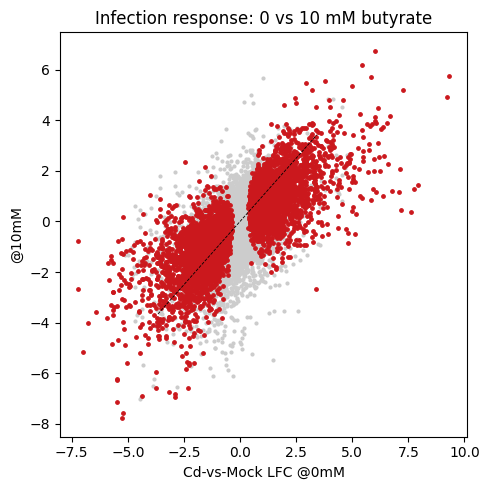

In [3]:
sig = i0.reindex(j.index)['padj']<0.05
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(j.loc[~sig,'log2FoldChange_0'], j.loc[~sig,'log2FoldChange_10'], s=4, c='#ccc')
ax.scatter(j.loc[sig,'log2FoldChange_0'],  j.loc[sig,'log2FoldChange_10'],  s=6, c='#cb181d')
lim=[j['log2FoldChange_0'].quantile(.01), j['log2FoldChange_0'].quantile(.99)]
ax.plot(lim,lim,'k--',lw=.6); ax.set_xlabel('Cd-vs-Mock LFC @0mM'); ax.set_ylabel('@10mM')
ax.set_title('Infection response: 0 vs 10 mM butyrate'); plt.tight_layout(); plt.show()

## Chemokines specifically — does the induction attenuate?

In [4]:
id2sym, sym2id = ac.load_symbol_map()
chemo = ['CXCL1','CXCL2','CXCL3','CXCL8','NFKB1','RELB','IRAK2','IKBKE']
rows=[]
for g in chemo:
    gid=sym2id.get(g)
    if gid in j.index: rows.append((g, j.loc[gid,'log2FoldChange_0'], j.loc[gid,'log2FoldChange_10'], j.loc[gid,'delta']))
pd.DataFrame(rows, columns=['gene','LFC@0','LFC@10','delta(10-0)']).round(2)

,gene,LFC@0,LFC@10,delta(10-0)
0,CXCL1,1.91,0.64,-1.27
1,CXCL2,3.56,0.88,-2.67
2,CXCL3,2.73,0.20,-2.53
3,CXCL8,4.09,1.90,-2.19
4,NFKB1,-0.08,-1.07,-0.99
5,RELB,1.11,1.16,0.04
6,IRAK2,2.03,2.79,0.75
7,IKBKE,1.19,0.16,-1.03


**Interpretation:** negative `delta` for chemokines (induction at 0 mM, reduced at 10 mM) = butyrate attenuates the inflammatory infection response → reproduces the A06 protective signature.